# <center> Experiment No-9

In [1]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

from scipy.cluster.hierarchy import linkage, dendrogram

# Seaborn style
sns.set_style("whitegrid")

# Matplotlib settings
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 100
plt.rcParams["font.size"] = 12

In [2]:
df = pd.read_csv("Wholesale customers data.csv")

In [3]:
print(df.head())

   Channel  Region  Fresh  Milk  Grocery  Frozen  Detergents_Paper  Delicassen
0        2       3  12669  9656     7561     214              2674        1338
1        2       3   7057  9810     9568    1762              3293        1776
2        2       3   6353  8808     7684    2405              3516        7844
3        1       3  13265  1196     4221    6404               507        1788
4        2       3  22615  5410     7198    3915              1777        5185


In [4]:
df.tail()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
435,1,3,29703,12051,16027,13135,182,2204
436,1,3,39228,1431,764,4510,93,2346
437,2,3,14531,15488,30243,437,14841,1867
438,1,3,10290,1981,2232,1038,168,2125
439,1,3,2787,1698,2510,65,477,52


In [5]:
df.columns

Index(['Channel', 'Region', 'Fresh', 'Milk', 'Grocery', 'Frozen',
       'Detergents_Paper', 'Delicassen'],
      dtype='object')

In [6]:
print("Dataset shape:", df.shape)

Dataset shape: (440, 8)


In [7]:
print(df.dtypes)

Channel             int64
Region              int64
Fresh               int64
Milk                int64
Grocery             int64
Frozen              int64
Detergents_Paper    int64
Delicassen          int64
dtype: object


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicassen        440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB


In [9]:
df.describe()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000
mean,1.322727,2.543182,12000.297727,5796.265909,7951.277273,3071.931818,2881.493182,1524.870455
std,0.468052,0.774272,12647.328865,7380.377175,9503.162829,4854.673333,4767.854448,2820.105937
min,1.000000,1.000000,3.000000,55.000000,3.000000,25.000000,3.000000,3.000000
25%,1.000000,2.000000,3127.750000,1533.000000,2153.000000,742.250000,256.750000,408.250000
50%,1.000000,3.000000,8504.000000,3627.000000,4755.500000,1526.000000,816.500000,965.500000
75%,2.000000,3.000000,16933.750000,7190.250000,10655.750000,3554.250000,3922.000000,1820.250000
max,2.000000,3.000000,112151.000000,73498.000000,92780.000000,60869.000000,40827.000000,47943.000000


In [10]:
df.isnull().sum()

Channel             0
Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicassen          0
dtype: int64

In [11]:
print("\nDuplicate rows:", df.duplicated().sum())


Duplicate rows: 0


In [12]:
X = df.drop(columns=["Channel", "Region"])
scaler=StandardScaler()
X_scaled=scaler.fit_transform(X)

In [13]:
X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=X.columns,
    index=X.index
)

In [14]:
display(X_scaled_df.head())

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,0.052933,0.523568,-0.041115,-0.589367,-0.043569,-0.066339
1,-0.391302,0.544458,0.170318,-0.270136,0.086407,0.089151
2,-0.447029,0.408538,-0.028157,-0.137536,0.133232,2.243293
3,0.100111,-0.624020,-0.392977,0.687144,-0.498588,0.093411
4,0.840239,-0.052396,-0.079356,0.173859,-0.231918,1.299347


In [15]:
print(X_scaled_df.mean().round(3))

Fresh              -0.0
Milk                0.0
Grocery            -0.0
Frozen              0.0
Detergents_Paper    0.0
Delicassen         -0.0
dtype: float64


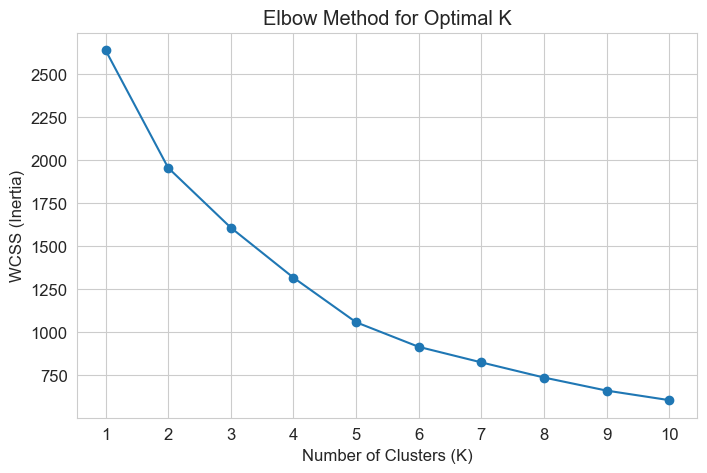

In [16]:
wcss=[]
k_values=range(1,11)
for k in k_values:
    kmeans=KMeans(n_clusters=k,random_state=42,n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)
plt.figure(figsize=(8, 5))
plt.plot(k_values, wcss, marker="o", linestyle="-")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS (Inertia)")
plt.title("Elbow Method for Optimal K")
plt.xticks(k_values)
plt.grid(True)
plt.show()
    

In [17]:
silhouette_values = []

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    silhouette_values.append(score)

silhouette_table = pd.DataFrame({
    "Number of Clusters": list(range(2, 11)),
    "Silhouette Score": silhouette_values
})

display(silhouette_table.round(4))

,Number of Clusters,Silhouette Score
0,2,0.5472
1,3,0.5483
2,4,0.3485
3,5,0.3690
4,6,0.3782
5,7,0.3343
6,8,0.3201
7,9,0.3090
8,10,0.3112


In [18]:
suggested_k = int(
    silhouette_table.loc[
        silhouette_table["Silhouette Score"].idxmax(),
        "Number of Clusters"
    ]
)

print("Suggested number of clusters:", suggested_k)

Suggested number of clusters: 3


In [19]:
K = suggested_k

kmeans_model = KMeans(
    n_clusters=K,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans_model.fit_predict(X_scaled)

In [20]:
df_kmeans = df.copy()

df_kmeans["kMeans_cluster"] = kmeans_labels

print("K-Means clustering completed successfully!")
print("\nCluster distribution:")
print(df_kmeans["kMeans_cluster"].value_counts().sort_index())

print("\nFirst five rows:")
display(df_kmeans.head())

K-Means clustering completed successfully!

Cluster distribution:
kMeans_cluster
0     45
1    393
2      2
Name: count, dtype: int64

First five rows:


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,kMeans_cluster
0,2,3,12669,9656,7561,214,2674,1338,1
1,2,3,7057,9810,9568,1762,3293,1776,1
2,2,3,6353,8808,7684,2405,3516,7844,1
3,1,3,13265,1196,4221,6404,507,1788,1
4,2,3,22615,5410,7198,3915,1777,5185,1


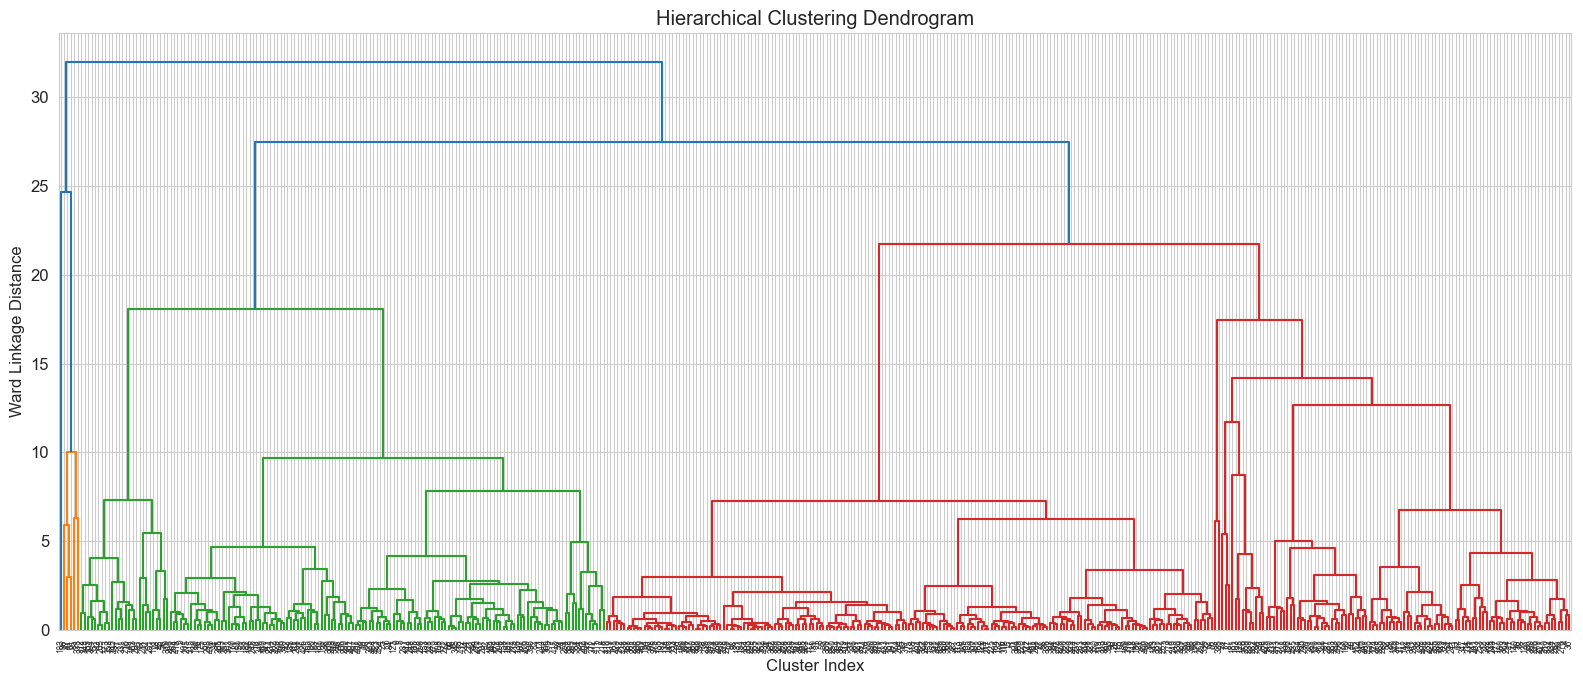

In [24]:
plt.figure(figsize=(16, 7))

Z = linkage(X_scaled, method="ward", metric="euclidean")

dendrogram(
    Z,
    leaf_rotation=90,
    leaf_font_size=6
)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Cluster Index")
plt.ylabel("Ward Linkage Distance")
plt.tight_layout()
plt.show()

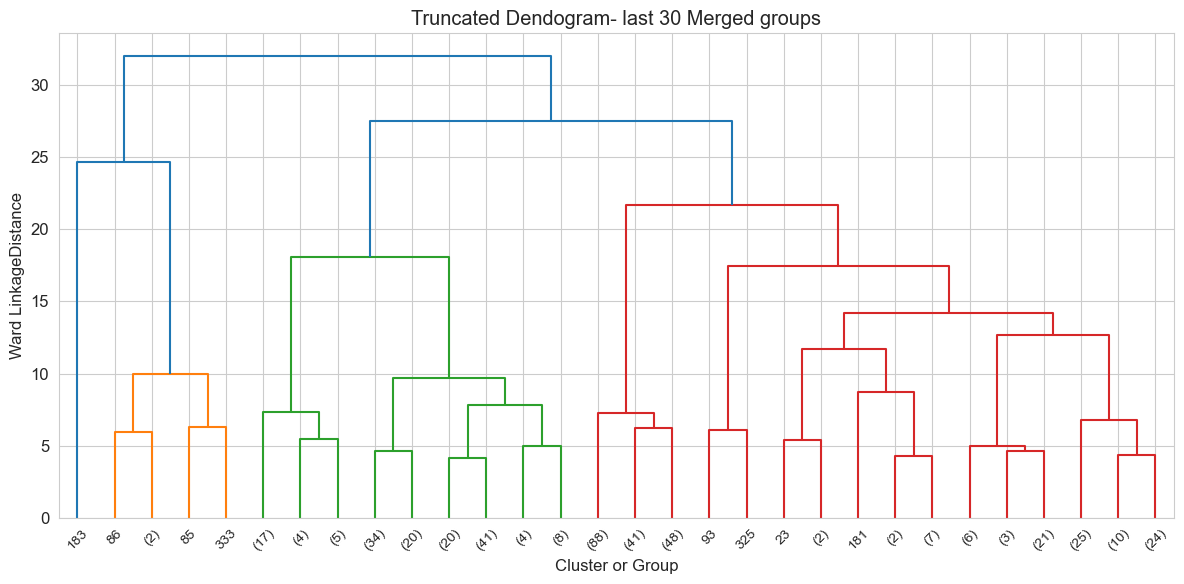

In [25]:
plt.figure(figsize=(12, 6))
dendrogram(
    Z,
    truncate_mode="lastp",
    p=30,
    show_leaf_counts=True,
    leaf_rotation=45
)

plt.title("Truncated Dendogram- last 30 Merged groups")
plt.xlabel("Cluster or Group")
plt.ylabel("Ward LinkageDistance")
plt.tight_layout()
plt.show()

In [27]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print(
    "Variance explained by each PCA component:",
    pca.explained_variance_ratio_.round(4)
)

print(
    "Total variance explained:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

Variance explained by each PCA component: [0.4408 0.2838]
Total variance explained: 72.46 %


In [28]:
pca_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "KMeans_Cluster": kmeans_labels
})

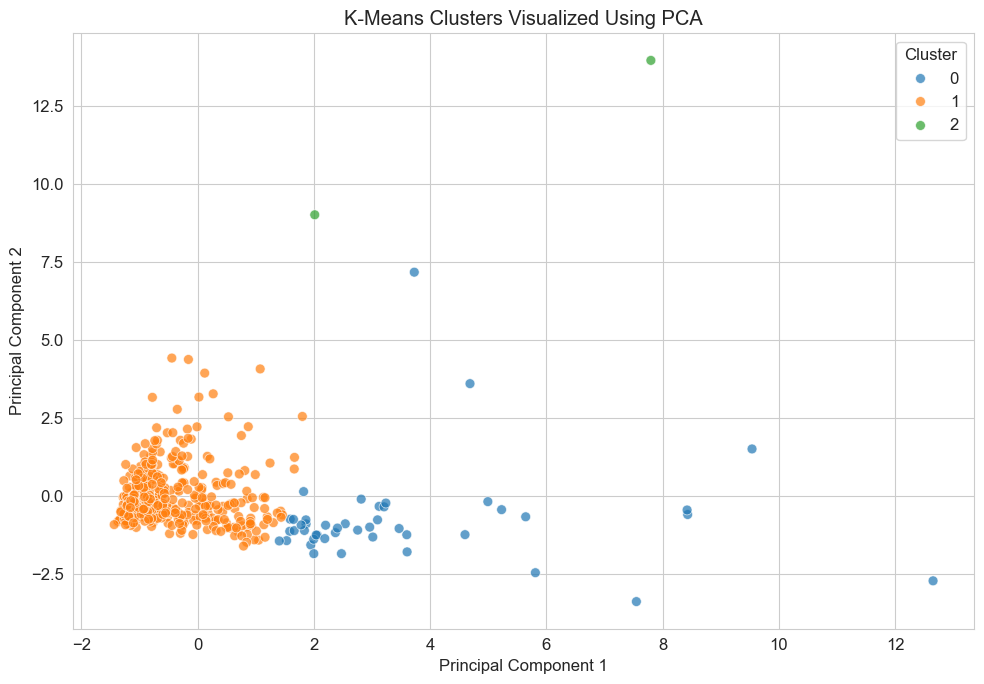

In [31]:
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="KMeans_Cluster",
    palette="tab10",
    s=50,
    alpha=0.7
)

plt.title("K-Means Clusters Visualized Using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

In [32]:
def evaluate_clustering(X_data, labels, model_name):
    return {
        "Algorithm": model_name,
        "Number of Clusters": len(set(labels)),
        "Silhouette Score": silhouette_score(X_data, labels)
    }

In [36]:
hierarchical_model = AgglomerativeClustering(
    n_clusters=suggested_k,
    linkage="ward"
)
hierarchical_labels = hierarchical_model.fit_predict(X_scaled)

In [37]:
comparison = pd.DataFrame([
    evaluate_clustering(X_scaled, kmeans_labels, "K-Means"),
    evaluate_clustering(X_scaled, hierarchical_labels, "Hierarchical")
])

display(comparison.round(4))

,Algorithm,Number of Clusters,Silhouette Score
0,K-Means,3,0.5483
1,Hierarchical,3,0.2646


In [39]:
# Compare cluster membership sizes
cluster_sizes = pd.DataFrame({
    "K-Means": pd.Series(kmeans_labels).value_counts().sort_index(),
    "Hierarchical": pd.Series(hierarchical_labels).value_counts().sort_index()
}).fillna(0).astype(int)

print("Cluster sizes:")
display(cluster_sizes)
# Calculate average spending for each K-Means cluster
kmeans_profile = df[features].copy()
kmeans_profile["Cluster"] = kmeans_labels

kmeans_means = kmeans_profile.groupby("Cluster")[features].mean().round(2)

print("Average spending profile of K-Means clusters:")
display(kmeans_means)

Cluster sizes:


,K-Means,Hierarchical
0,45,6
1,393,281
2,2,153


NameError: name 'features' is not defined